In [3]:
import sys
import torch
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from ultralytics import YOLO

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device: CPU")
print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Python: /Users/startup/miniconda3/envs/yolotest/bin/python
PyTorch: 2.2.2
OpenCV: 4.10.0
CUDA available: False
Device: CPU
All libraries imported successfully!


In [4]:
from ultralytics import YOLO

# Load lightweight YOLO model for CPU inference
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


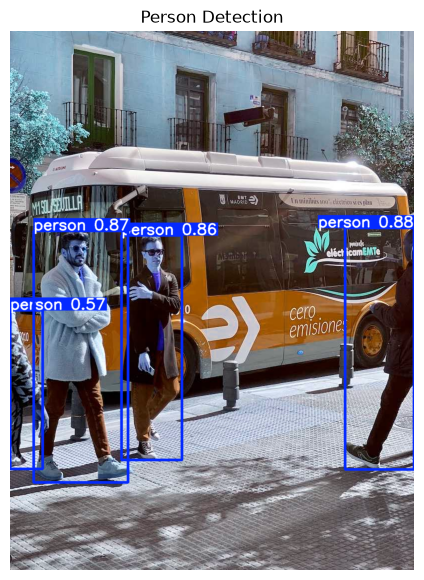

People detected: 4


In [5]:
import cv2
import matplotlib.pyplot as plt

# Load a sample image
image_url = "https://ultralytics.com/images/bus.jpg"
image = cv2.cvtColor(
    cv2.imread(image_url) if False else
    cv2.imdecode(
        __import__("numpy").frombuffer(
            __import__("urllib.request", fromlist=["urlopen"])
            .urlopen(image_url).read(),
            dtype="uint8"
        ),
        cv2.IMREAD_COLOR
    ),
    cv2.COLOR_BGR2RGB
)

# Detect people (COCO class ID 0 = person)
results = model.predict(
    source=image,
    classes=[0],
    device="cpu",
    conf=0.25,
    verbose=False
)

# Display detections
annotated_image = results[0].plot()
annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("Person Detection")
plt.show()

print("People detected:", len(results[0].boxes))

In [7]:
from pathlib import Path
from ultralytics import YOLO

# Correct dataset path
DATASET_DIR = Path.cwd() / "dataset" / "images"

# Output directory
OUTPUT_DIR = Path.cwd() / "runs" / "person_detection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Find images
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = sorted(
    p for p in DATASET_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
)

print("Images found:", len(image_paths))

# Run person detection and save annotated images
model = YOLO("yolo11n.pt")

for image_path in image_paths:
    results = model.predict(
        source=str(image_path),
        classes=[0],
        device="cpu",
        imgsz=640,
        conf=0.25,
        save=False,
        verbose=False
    )

    annotated_image = results[0].plot()

    output_path = OUTPUT_DIR / image_path.name
    import cv2
    cv2.imwrite(str(output_path), annotated_image)

    print(f"{image_path.name}: {len(results[0].boxes)} people detected")

print("\nAll detections completed!")
print("Results saved to:", OUTPUT_DIR)

Images found: 6
construction_worker.jpg: 1 people detected
coworkers_in_office.jpg: 3 people detected
family_outdoors.jpg: 4 people detected
pedestrians_crossing.jpg: 9 people detected
people_in_mall.jpg: 8 people detected
people_on_campus.jpg: 4 people detected

All detections completed!
Results saved to: /Users/startup/projects/yolotest/runs/person_detection
